In [12]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display, clear_output
import ipywidgets as widgets

print("Python:", os.sys.executable)
print("Working directory:", os.getcwd())
print("Libraries imported successfully!")

Python: /home/krisjscott/semantic-faq-env/bin/python
Working directory: /home/krisjscott/Downloads
Libraries imported successfully!


In [13]:
def locate_file(filename):
    possible_paths = [
        Path.cwd() / filename,
        Path("/mnt/data") / filename
    ]

    for path in possible_paths:
        if path.is_file():
            return path

    raise FileNotFoundError(
        f"Cannot find {filename}. "
        "Place the CSV in your notebook folder or /mnt/data."
    )


FAQ_FILE = locate_file("semantic_faq_dataset (1).csv")
ORIGINAL_TEST_FILE = locate_file(
    "semantic_faq_test_queries (1).csv"
)
ADDITIONAL_TEST_FILE = locate_file(
    "semantic_faq_additional_test_queries.csv"
)
NO_MATCH_FILE = locate_file(
    "semantic_faq_no_match_test_queries.csv"
)


def load_csv(path):
    df = pd.read_csv(path)
    df.columns = df.columns.astype(str).str.strip().str.lower()

    # Remove empty spreadsheet columns
    df = df.loc[
        :, ~df.columns.str.match(r"^unnamed")
    ].copy()

    return df


faqs_df = load_csv(FAQ_FILE)
original_test_df = load_csv(ORIGINAL_TEST_FILE)
additional_test_df = load_csv(ADDITIONAL_TEST_FILE)
no_match_df = load_csv(NO_MATCH_FILE)


# Validate FAQ structure
required_faq_columns = {"faq_id", "question", "answer"}

if not required_faq_columns.issubset(faqs_df.columns):
    raise ValueError(
        f"FAQ columns found: {faqs_df.columns.tolist()}. "
        f"Required: {sorted(required_faq_columns)}"
    )

# Category is optional
if "category" not in faqs_df.columns:
    faqs_df["category"] = "General"

# Remove incomplete records and clean text
faqs_df = faqs_df.dropna(
    subset=["faq_id", "question", "answer"]
).copy()

for column in ["faq_id", "question", "answer", "category"]:
    faqs_df[column] = faqs_df[column].astype(str).str.strip()

if faqs_df["faq_id"].duplicated().any():
    raise ValueError("Duplicate FAQ IDs found. Resolve them before evaluation.")

if faqs_df.empty:
    raise ValueError("The FAQ dataset is empty.")

# Validate test datasets
for name, df in [
    ("Original tests", original_test_df),
    ("Additional tests", additional_test_df)
]:
    required = {"user_query", "expected_faq_id"}

    if not required.issubset(df.columns):
        raise ValueError(
            f"{name} has unexpected columns: {df.columns.tolist()}"
        )

if "user_query" not in no_match_df.columns:
    raise ValueError("The no-match CSV must contain user_query.")


# Normalize IDs to avoid mismatches caused by whitespace
faqs_df["faq_id"] = faqs_df["faq_id"].str.strip().str.upper()

for df in [original_test_df, additional_test_df]:
    df["expected_faq_id"] = (
        df["expected_faq_id"].astype(str).str.strip().str.upper()
    )
    df["user_query"] = df["user_query"].astype(str).str.strip()

no_match_df["user_query"] = (
    no_match_df["user_query"].astype(str).str.strip()
)

print("DATASETS LOADED")
print("-" * 40)
print("FAQs:", len(faqs_df))
print("Unique categories:", faqs_df["category"].nunique())
print("Original test queries:", len(original_test_df))
print("Additional test queries:", len(additional_test_df))
print("No-match queries:", len(no_match_df))

print("\nFAQs by category:")
display(
    faqs_df.groupby("category").size()
    .reset_index(name="FAQ count")
)

display(faqs_df.head())

DATASETS LOADED
----------------------------------------
FAQs: 98
Unique categories: 10
Original test queries: 20
Additional test queries: 106
No-match queries: 20

FAQs by category:


,category,FAQ count
0,Account,10
1,Customer Support,10
2,Delivery,10
3,General,10
4,Order Tracking,10
5,Payments,10
6,Privacy and Security,8
7,Products,10
8,Refunds,10
9,Returns,10


,faq_id,category,question,answer
0,ORD001,Order Tracking,How can I track my order?,"Open the Orders section of your account, selec..."
1,ORD002,Order Tracking,Where is my parcel right now?,Open your order details and use the tracking l...
2,ORD003,Order Tracking,How do I find my tracking number?,Your tracking number is shown in the shipping ...
3,ORD004,Order Tracking,Why has my tracking status not changed?,Carrier tracking may take time to update. Chec...
4,ORD005,Order Tracking,My order says delivered but I did not receive ...,Check with household members or your building ...


In [14]:
from sentence_transformers import SentenceTransformer, util

MODEL_NAME = "all-MiniLM-L6-v2"

model = SentenceTransformer(MODEL_NAME)

faq_questions = faqs_df["question"].tolist()

# Generate FAQ embeddings once
faq_embeddings = model.encode(
    faq_questions,
    convert_to_tensor=True,
    normalize_embeddings=True,
    show_progress_bar=True
)

print("Model:", MODEL_NAME)
print("FAQ embeddings generated:", len(faq_questions))
print("Embedding dimensions:", faq_embeddings.shape[-1])

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Model: all-MiniLM-L6-v2
FAQ embeddings generated: 98
Embedding dimensions: 384


In [15]:
SIMILARITY_THRESHOLD = 0.45

def tokenize(text):
    return set(re.findall(r"\b[a-z0-9]+\b", str(text).lower()))


faq_word_sets = [
    tokenize(question)
    for question in faq_questions
]


def find_answer(user_question, threshold=None):
    if threshold is None:
        threshold = SIMILARITY_THRESHOLD

    query = str(user_question).strip()

    if not query:
        return {
            "status": "Invalid query",
            "faq_id": None,
            "matched_question": None,
            "answer": "Please enter a question.",
            "category": None,
            "similarity": 0.0,
            "top_matches": []
        }

    query_embedding = model.encode(
        query,
        convert_to_tensor=True,
        normalize_embeddings=True
    )

    semantic_scores = util.cos_sim(
        query_embedding,
        faq_embeddings
    )[0].cpu().numpy()

    query_words = tokenize(query)

    keyword_scores = np.array([
        len(query_words & faq_words) / len(query_words)
        if query_words else 0.0
        for faq_words in faq_word_sets
    ])

    combined_scores = (
        0.85 * semantic_scores
        + 0.15 * keyword_scores
    )

    ranked_indices = np.argsort(combined_scores)[::-1]
    best_index = int(ranked_indices[0])
    best_score = float(combined_scores[best_index])

    top_matches = []

    for index in ranked_indices[:3]:
        faq = faqs_df.iloc[int(index)]

        top_matches.append({
            "faq_id": faq["faq_id"],
            "question": faq["question"],
            "category": faq["category"],
            "score": round(float(combined_scores[index]), 4)
        })

    if best_score < threshold:
        return {
            "status": "No suitable match",
            "faq_id": None,
            "matched_question": None,
            "answer": (
                "I couldn't find a suitable FAQ. "
                "Please rephrase your question or contact support."
            ),
            "category": None,
            "similarity": round(best_score, 4),
            "top_matches": top_matches
        }

    faq = faqs_df.iloc[best_index]

    return {
        "status": "Match found",
        "faq_id": faq["faq_id"],
        "matched_question": faq["question"],
        "answer": faq["answer"],
        "category": faq["category"],
        "similarity": round(best_score, 4),
        "top_matches": top_matches
    }


print("FAQ matcher is ready!")

FAQ matcher is ready!


In [16]:
sample_questions = [
    "Where is my order?",
    "How can I get a refund?",
    "I want to return a product.",
    "My payment failed. What should I do?",
    "I forgot my password.",
    "Can I change my delivery address?",
    "What is the capital of France?"
]

for question in sample_questions:
    result = find_answer(question)

    print("\nQuestion:", question)
    print("Status:", result["status"])
    print("FAQ ID:", result["faq_id"])
    print("Matched FAQ:", result["matched_question"])
    print("Score:", result["similarity"])
    print("Answer:", result["answer"])
    print("-" * 60)


Question: Where is my order?
Status: Match found
FAQ ID: ORD002
Matched FAQ: Where is my parcel right now?
Score: 0.6401
Answer: Open your order details and use the tracking link to view the latest carrier update.
------------------------------------------------------------

Question: How can I get a refund?
Status: Match found
FAQ ID: REF003
Matched FAQ: Where can I check my refund status?
Score: 0.749
Answer: Open your order or returns page and look for the refund status.
------------------------------------------------------------

Question: I want to return a product.
Status: Match found
FAQ ID: RET001
Matched FAQ: How can I return a product?
Score: 0.8988
Answer: Open your order details and select Return Item if the product is eligible.
------------------------------------------------------------

Question: My payment failed. What should I do?
Status: Match found
FAQ ID: PAY002
Matched FAQ: Why was my payment declined?
Score: 0.589
Answer: Verify your payment details, available f

In [17]:
valid_faq_ids = set(faqs_df["faq_id"])


def evaluate_matching(test_df, dataset_name):
    records = []

    for _, row in test_df.iterrows():
        query = row["user_query"]
        expected_id = row["expected_faq_id"]

        result = find_answer(query)

        # The highest-ranked candidate, regardless of threshold
        top1_id = result["top_matches"][0]["faq_id"]

        top3_ids = [
            item["faq_id"]
            for item in result["top_matches"]
        ]

        expected_exists = expected_id in valid_faq_ids

        records.append({
            "user_query": query,
            "expected_faq_id": expected_id,
            "expected_id_exists": expected_exists,
            "top1_faq_id": top1_id,
            "predicted_faq_id": result["faq_id"],
            "score": result["similarity"],
            "status": result["status"],
            "top1_correct": (
                top1_id == expected_id if expected_exists else None
            ),
            "top3_correct": (
                expected_id in top3_ids if expected_exists else None
            ),
            "accepted_match_correct": (
                result["faq_id"] == expected_id
                if expected_exists else None
            )
        })

    results = pd.DataFrame(records)

    valid = results[results["expected_id_exists"]].copy()
    invalid = results[~results["expected_id_exists"]].copy()

    print("\n" + "=" * 55)
    print(dataset_name)
    print("=" * 55)
    print("Total queries:", len(results))
    print("Queries with valid expected IDs:", len(valid))
    print("Queries with invalid expected IDs:", len(invalid))

    if not valid.empty:
        top1_accuracy = 100 * valid["top1_correct"].mean()
        top3_accuracy = 100 * valid["top3_correct"].mean()
        accepted_accuracy = (
            100 * valid["accepted_match_correct"].mean()
        )

        print(f"Top-1 accuracy: {top1_accuracy:.2f}%")
        print(f"Top-3 accuracy: {top3_accuracy:.2f}%")
        print(
            "Correct matches after threshold: "
            f"{accepted_accuracy:.2f}%"
        )

    if not invalid.empty:
        print("\nWARNING: These expected FAQ IDs are missing:")
        display(invalid[["user_query", "expected_faq_id"]])

    return results


original_results = evaluate_matching(
    original_test_df,
    "Original Test Set"
)

additional_results = evaluate_matching(
    additional_test_df,
    "Additional Test Set"
)

display(additional_results)


Original Test Set
Total queries: 20
Queries with valid expected IDs: 19
Queries with invalid expected IDs: 1
Top-1 accuracy: 73.68%
Top-3 accuracy: 89.47%
Correct matches after threshold: 73.68%



,user_query,expected_faq_id
5,I want to stop my order,ORD011



Additional Test Set
Total queries: 106
Queries with valid expected IDs: 106
Queries with invalid expected IDs: 0
Top-1 accuracy: 81.13%
Top-3 accuracy: 96.23%
Correct matches after threshold: 78.30%


,user_query,expected_faq_id,expected_id_exists,top1_faq_id,predicted_faq_id,score,status,top1_correct,top3_correct,accepted_match_correct
0,Can you show me the latest location of my ship...,ORD001,True,ORD010,ORD010,0.5825,Match found,False,True,False
1,I need to follow my online order,ORD001,True,ORD001,ORD001,0.6403,Match found,True,True,True
2,Where do I see the courier tracking details?,ORD003,True,ORD003,ORD003,0.5584,Match found,True,True,True
3,I cannot find the tracking code for my package,ORD003,True,ORD003,ORD003,0.6066,Match found,True,True,True
4,The tracking page has been stuck for two days,ORD004,True,ORD004,ORD004,0.5705,Match found,True,True,True
...,...,...,...,...,...,...,...,...,...,...
101,Is there a new customer discount for my first ...,GEN006,True,GEN006,GEN006,0.7212,Match found,True,True,True
102,Where can I find the latest deals and promotions?,GEN007,True,GEN007,GEN007,0.5728,Match found,True,True,True
103,How do I share my experience with the store?,GEN008,True,GEN008,GEN008,0.6669,Match found,True,True,True
104,Where can I read the full terms of use?,GEN009,True,GEN009,GEN009,0.4838,Match found,True,True,True


In [18]:
def evaluate_no_match(test_df):
    records = []

    for query in test_df["user_query"]:
        result = find_answer(query)

        records.append({
            "user_query": query,
            "predicted_faq_id": result["faq_id"],
            "score": result["similarity"],
            "status": result["status"],
            "correctly_rejected": (
                result["status"] == "No suitable match"
            )
        })

    results = pd.DataFrame(records)

    total = len(results)
    rejected = int(results["correctly_rejected"].sum())
    accepted = total - rejected

    print("\nNO-MATCH EVALUATION")
    print("-" * 40)
    print("Total unrelated queries:", total)
    print("Correctly rejected:", rejected)
    print("Incorrectly accepted:", accepted)
    print(
        "Rejection rate: "
        f"{100 * rejected / total if total else 0:.2f}%"
    )

    return results


no_match_results = evaluate_no_match(no_match_df)

display(no_match_results)


NO-MATCH EVALUATION
----------------------------------------
Total unrelated queries: 20
Correctly rejected: 20
Incorrectly accepted: 0
Rejection rate: 100.00%


,user_query,predicted_faq_id,score,status,correctly_rejected
0,What is the weather forecast for tomorrow?,None,0.2244,No suitable match,True
1,Who won the football match last night?,None,0.1844,No suitable match,True
2,Can you explain quantum entanglement?,None,0.1856,No suitable match,True
3,Write me a poem about the ocean,None,0.1460,No suitable match,True
4,How do I apply for a passport?,None,0.3351,No suitable match,True
5,What is the capital city of Japan?,None,0.1350,No suitable match,True
6,Can you solve this calculus equation?,None,0.1887,No suitable match,True
7,Tell me a joke about programmers,None,0.1405,No suitable match,True
8,How do I install Linux on my laptop?,None,0.2384,No suitable match,True
9,What are the symptoms of seasonal allergies?,None,0.2177,No suitable match,True


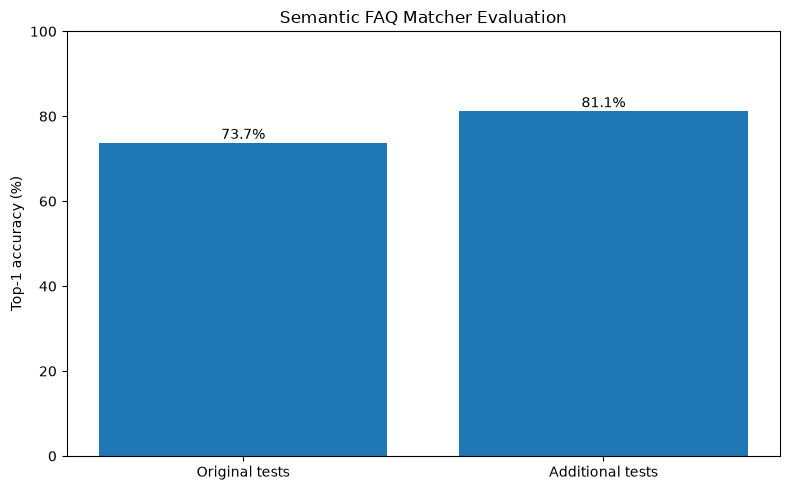

In [19]:
plot_names = []
plot_accuracies = []

for name, results in [
    ("Original tests", original_results),
    ("Additional tests", additional_results)
]:
    valid = results[results["expected_id_exists"]]

    if not valid.empty:
        plot_names.append(name)
        plot_accuracies.append(
            100 * valid["top1_correct"].mean()
        )

plt.figure(figsize=(8, 5))
bars = plt.bar(plot_names, plot_accuracies)

plt.ylim(0, 100)
plt.ylabel("Top-1 accuracy (%)")
plt.title("Semantic FAQ Matcher Evaluation")

for bar, value in zip(bars, plot_accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [20]:
question_input = widgets.Textarea(
    placeholder="Example: How can I get a refund?",
    description="Question:",
    layout=widgets.Layout(width="90%", height="80px")
)

search_button = widgets.Button(
    description="Find Answer",
    button_style="primary",
    icon="search"
)

output = widgets.Output()


def on_search_clicked(button):
    with output:
        clear_output(wait=True)

        query = question_input.value.strip()

        if not query:
            print("Please enter a question.")
            return

        result = find_answer(query)

        print("Status:", result["status"])
        print("Combined score:", result["similarity"])

        if result["matched_question"] is not None:
            print("FAQ ID:", result["faq_id"])
            print("Category:", result["category"])
            print("\nMatched question:")
            print(result["matched_question"])

        print("\nAnswer:")
        print(result["answer"])

        print("\nTop three FAQ candidates:")
        display(pd.DataFrame(result["top_matches"]))


search_button.on_click(on_search_clicked)

display(widgets.VBox([
    widgets.HTML("<h2>Semantic FAQ Matcher</h2>"),
    question_input,
    search_button,
    output
]))